In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib
from wordcloud import WordCloud

서울특별시는 4급 부서장 이상의 간부직 공무원의 업무 추진비 집행 내역을 활용해서 업무 추진비의 사용 목적과 사용한 장소를 분석한다.

공공 데이터 포털: https://www.data.go.kr/  
서울 열린 데이터 광장: https://data.seoul.go.kr/  
서울 정보 소통 광장: https://opengov.seoul.go.kr/

# 분석할 데이터를 읽어서 전처리한다.

분석할 데이터가 저장된 CSV 파일을 읽어서 데이터프레임으로 만든다.

In [2]:
raw_df = pd.read_csv('./data/raw.csv')
print(raw_df.shape)
raw_df.head()

(51456, 10)


,1소속부서,결제방법,구분,대상인원,부서명,일련번호,집행금액,집행목적,집행일시,집행장소
0,서울특별시장,카드,시정 관련 간담회 등,시장 등 12명,행정국 총무과,1,344000.0,시정 정책추진 자문 간담회,2018-01-19 20:41,동신참치양재직(서초구 강남대로 213)
1,서울특별시장,카드,시정 관련 간담회 등,"시장, 청년단체 등 38명",행정국 총무과,2,450000.0,시정 청년 정책 의견수렴 간담회,2018-01-23 19:06,서울시청구내식당 ( 중구 세종대로 110)
2,서울특별시장,카드,시정 관련 간담회 등,시장 등 8명,행정국 총무과,3,226000.0,시정 주요 경제정책 현안추진 의견수렴 간담회,2018-01-29 20:13,한뫼촌(종로구 북촌로)
3,서울특별시장,카드,시정 관련 간담회 등,시장 등 11명,행정국 총무과,4,324500.0,시정종교계 의견수렴 간담회,2018-01-12 09:09,서울시청구내식당(중구 세종대로 110)
4,서울특별시장,카드,시정 관련 간담회 등,시장 등 25명,행정국 총무과,5,737500.0,시정 정책 추진 의견수렴 간담회,2018-01-12 09:10,서울시청구내식당(중구 세종대로 110)


CSV 파일을 읽어올 때 데이터프레임의 행 인덱스를 자동으로 부여하지 않고 데이터 열 중 하나를 선택해서 인덱스로 지정할 수 있다.

raw_df = pd.read_csv('./data/raw.csv', index_col='일련번호')  
print(raw_df.shape)  
raw_df.head()

'1소속부서' 열의 이름을 '소속부서'로 수정한다.

rename() 메소드의 `columns`에 기존 열 이름을 key로 하고 수정할 열 이름을 value로 하는 딕셔너리를 넘겨준다.

In [3]:
# raw_df.columns = ['소속부서', '결제방법', '구분', '대상인원', '부서명', '일련번호', '금액', '목적', '일시', '장소']
raw_df.rename(columns={'1소속부서': '소속부서'}, inplace=True)
raw_df.columns

Index(['소속부서', '결제방법', '구분', '대상인원', '부서명', '일련번호', '집행금액', '집행목적', '집행일시',
       '집행장소'],
      dtype='str')

dtypes 속성이나 info() 메소드로 분석할 데이터의 정보를 확인한다.

In [4]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51456 entries, 0 to 51455
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   소속부서    51456 non-null  str    
 1   결제방법    51279 non-null  str    
 2   구분      1479 non-null   str    
 3   대상인원    51448 non-null  str    
 4   부서명     51454 non-null  str    
 5   일련번호    51456 non-null  str    
 6   집행금액    51455 non-null  float64
 7   집행목적    51440 non-null  str    
 8   집행일시    51455 non-null  str    
 9   집행장소    51421 non-null  str    
dtypes: float64(1), str(9)
memory usage: 3.9 MB


누락값 현황을 확인한다.

In [5]:
raw_df.isnull().sum()

소속부서        0
결제방법      177
구분      49977
대상인원        8
부서명         2
일련번호        0
집행금액        1
집행목적       16
집행일시        1
집행장소       35
dtype: int64

누락값 현황을 시각화하기 위해서 missingno 라이브러리를 설치하고 import 한다.  
`!pip install missingno`

In [6]:
import missingno as msno

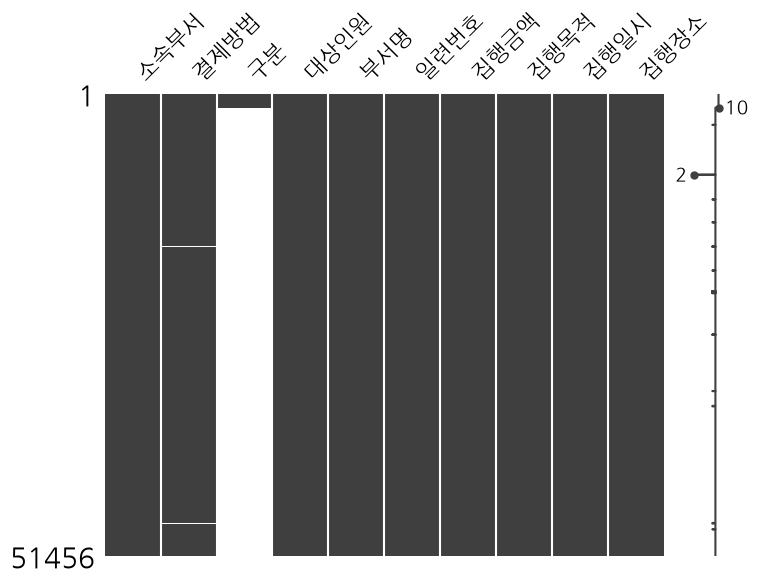

In [7]:
msno.matrix(raw_df, figsize=[8, 6])
plt.show()

누락값이 많이 포함된 불필요한 `구분` 열과 중복되는 일련번호가 저장된 `일련번호` 열을 제거한다.

In [8]:
raw_df.drop(columns=['구분', '일련번호'], inplace=True)
raw_df.columns

Index(['소속부서', '결제방법', '대상인원', '부서명', '집행금액', '집행목적', '집행일시', '집행장소'],
      dtype='str')

In [9]:
raw_df[raw_df.집행일시.isnull()]

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소
8958,서울혁신기획관,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
raw_df[raw_df.집행일시.isnull()].소속부서

8958    서울혁신기획관
Name: 소속부서, dtype: str

누락값이 많이 포함된 불필요한 행을 제거한다.

In [11]:
print(raw_df.shape)
raw_df.drop(raw_df[raw_df.집행일시.isnull()].index[0], inplace=True)
print(raw_df.shape)

(51456, 8)
(51455, 8)


날짜, 시간 단위의 데이터 분석을 하기 위해서 집행일시 열의 데이터 타입을 str에서 datetime으로 변경한다.

In [12]:
raw_df['집행일시'] = pd.to_datetime(raw_df.집행일시, format='mixed')
raw_df.dtypes

소속부서               str
결제방법               str
대상인원               str
부서명                str
집행금액           float64
집행목적               str
집행일시    datetime64[us]
집행장소               str
dtype: object

집행일시 열을 이용해서 '년', '월', '일', '년월', '시', '분', '요일'이라는 파생 변수를 만든다.

In [13]:
print('2018-01-19 20:41'.split())
print('2018-01-19 20:41'.split()[0].split('-'))
print('2018-01-19 20:41'.split()[1].split(':'))

['2018-01-19', '20:41']
['2018', '01', '19']
['20', '41']


In [14]:
from datetime import datetime as dt

In [15]:
now = dt.now()
print(now)
print(now.year)
print(now.month)
print(now.day)
print(now.hour)
print(now.minute)
print(now.second)
print(now.microsecond)
print(now.microsecond // 1000)
print(now.weekday()) # 요일, 0(월), 1(화), 2(수), 3(목), 4(금), 5(토), 6(일)

2026-11-11 15:13:18.933246
2026
11
11
15
13
18
933246
933
2


In [16]:
print(type(raw_df.집행일시))
# 데이터 타입이 datetime인 시리즈에 날짜 및 시간 관련 속성 또는 메소드를 적용하려면 dt를 붙여서 일시적으로 시리즈를 datetime 타입으로 바꿔줘야 한다.
print(type(raw_df.집행일시.dt))
print(raw_df.집행일시.dt.year)
# datetime 타입으로 바꿔서 날짜 및 시간 관련 속성 또는 메소드를 적용하면 다시 시리즈로 돌아간다.
print(type(raw_df.집행일시.dt.year))

<class 'pandas.Series'>
<class 'pandas.core.indexes.accessors.DatetimeProperties'>
0        2018
1        2018
2        2018
3        2018
4        2018
         ... 
51451    2016
51452    2016
51453    2016
51454    2016
51455    2016
Name: 집행일시, Length: 51455, dtype: int32
<class 'pandas.Series'>


In [17]:
raw_df['년'] = raw_df.집행일시.dt.year
raw_df['월'] = raw_df.집행일시.dt.month
raw_df['일'] = raw_df.집행일시.dt.day
raw_df['년월'] = raw_df.집행일시.dt.year.astype(str) + '-' + raw_df.집행일시.dt.month.astype(str)
raw_df['시'] = raw_df.집행일시.dt.hour
raw_df['분'] = raw_df.집행일시.dt.minute
# raw_df['요일'] = raw_df.집행일시.dt.weekday
raw_df['요일'] = raw_df.집행일시.dt.dayofweek

In [18]:
raw_df

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일
0,서울특별시장,카드,시장 등 12명,행정국 총무과,344000.0,시정 정책추진 자문 간담회,2018-01-19 20:41:00,동신참치양재직(서초구 강남대로 213),2018,1,19,2018-1,20,41,4
1,서울특별시장,카드,"시장, 청년단체 등 38명",행정국 총무과,450000.0,시정 청년 정책 의견수렴 간담회,2018-01-23 19:06:00,서울시청구내식당 ( 중구 세종대로 110),2018,1,23,2018-1,19,6,1
2,서울특별시장,카드,시장 등 8명,행정국 총무과,226000.0,시정 주요 경제정책 현안추진 의견수렴 간담회,2018-01-29 20:13:00,한뫼촌(종로구 북촌로),2018,1,29,2018-1,20,13,0
3,서울특별시장,카드,시장 등 11명,행정국 총무과,324500.0,시정종교계 의견수렴 간담회,2018-01-12 09:09:00,서울시청구내식당(중구 세종대로 110),2018,1,12,2018-1,9,9,4
4,서울특별시장,카드,시장 등 25명,행정국 총무과,737500.0,시정 정책 추진 의견수렴 간담회,2018-01-12 09:10:00,서울시청구내식당(중구 세종대로 110),2018,1,12,2018-1,9,10,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51451,시민건강국,카드,보건의료정책 직원 4명,시민건강국 보건의료정책과,110000.0,보건의료정책과 2016년 종무식 추진관련 직원격려물품 구입비 지급,2016-12-29 13:23:00,올리브네트웍스 (중구 세종대로 16길),2016,12,29,2016-12,13,23,3
51452,시민건강국,카드,시민건강국장 외 7명,시민건강국 보건의료정책과,118000.0,2017년 신년업무보고 계획 논의 간담회비 지급,2016-12-29 21:19:00,남도한식고운님 (중구 세종대로 82),2016,12,29,2016-12,21,19,3
51453,시민건강국,카드,시민건강국장 외 6명,시민건강국 보건의료정책과,174000.0,시민건강국 간부 송년 오찬간담회비 지급,2016-12-30 13:04:00,춘산에프앤비 (중구 태평로1가 84),2016,12,30,2016-12,13,4,4
51454,시민건강국,카드,보건의료정책과 직원,시민건강국 보건의료정책과,30000.0,보건의료정책과 2016년 종무식 추진관련 직원격려물품 구입비 지급,2016-12-30 13:13:00,스타벅스 (중구 을지로 19),2016,12,30,2016-12,13,13,4


# 시각화를 통해서 데이터를 분석한다.

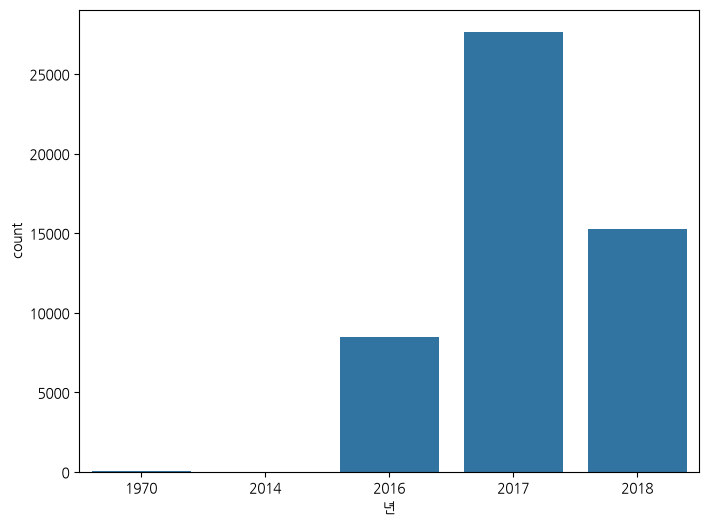

In [19]:
plt.figure(figsize=[8, 6])
sns.countplot(data=raw_df, x='년')
plt.show()

In [20]:
raw_df[raw_df.년 == 1970]

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일
312,서울특별시장,카드,시장 등 3명,행정국 총무과,34000.0,시정 현장방문 관련 업무협의,1970-01-01 09:00:00,뼈큰감자탕 (대구 중구 명덕로),1970,1,1,1970-1,9,0,3
371,서울특별시장,카드,시장 등 4명,행정국 총무과,118000.0,시정 정책 추진 자문 간담회,1970-01-01 09:00:00,서울시청구내식당,1970,1,1,1970-1,9,0,3
398,서울특별시장,카드,직원 26명,행정국 총무과,130000.0,한양조성 도감 추진 노고 직원 격려,1970-01-01 09:00:00,빚은 (중구 세종대로길),1970,1,1,1970-1,9,0,3
408,서울특별시장,카드,시장 등 7명,행정국 총무과,151400.0,시정 일정 및 현장방문 관련 업무협의,1970-01-01 09:00:00,본도시락 (중구 소공로길),1970,1,1,1970-1,9,0,3
409,서울특별시장,현금,직원 1명,행정국 총무과,1000000.0,사망직원 유족 위로금 지급,1970-01-01 09:00:00,-,1970,1,1,1970-1,9,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41017,행정국,카드,전직원,일력개발과,66000.0,2016 인력개발과 종무식 다과비 지급,1970-01-01 09:00:00,서울시청매점 (중구 서소문동),1970,1,1,1970-1,9,0,3
41018,행정국,카드,전직원,일력개발과,66000.0,인력개발과 종무식 다과비 지급,1970-01-01 09:00:00,서울시청신매점 (중구 세종대로),1970,1,1,1970-1,9,0,3
42515,행정국,카드,의전팀장 등 3명,행정국 총무과,39000.0,대한노인회 서울시연합회 정기총회 의전지원 업무협의,1970-01-01 09:00:00,먹는세상 (용산구 효창원로),1970,1,1,1970-1,9,0,3
42774,행정국,카드,행정국장 등 4명,행정국 총무과,29000.0,시민카드 운영 관련 업무협의,1970-01-01 09:00:00,별미삼청수제비 (종로구 삼청로길),1970,1,1,1970-1,9,0,3


In [21]:
raw_df[raw_df.년 == 2014]

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일
16772,비상기획관,카드,"민방위담당관, 주ㅇㅇ주무관등 16명",민방위담당관,64000.0,제407차 민방위의 날 전국 지진대피훈련 관련 간담회,2014-04-23 10:41:00,서울시청구내식당(중구 세종대로),2014,4,23,2014-4,10,41,2


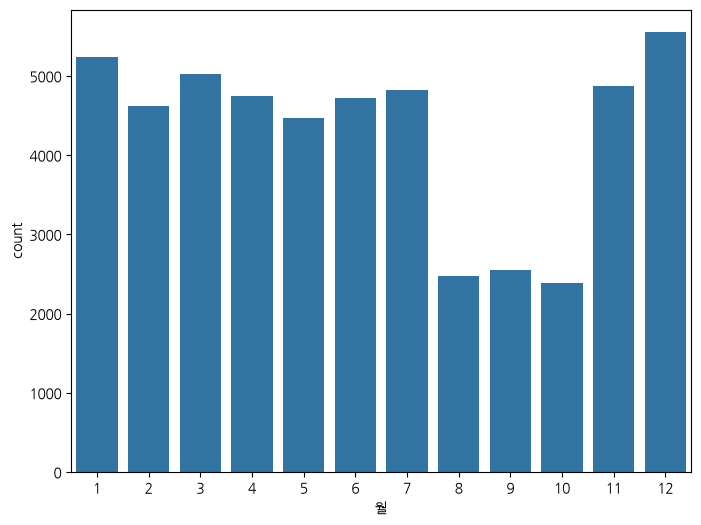

In [22]:
plt.figure(figsize=[8, 6])
sns.countplot(data=raw_df, x='월')
plt.show()

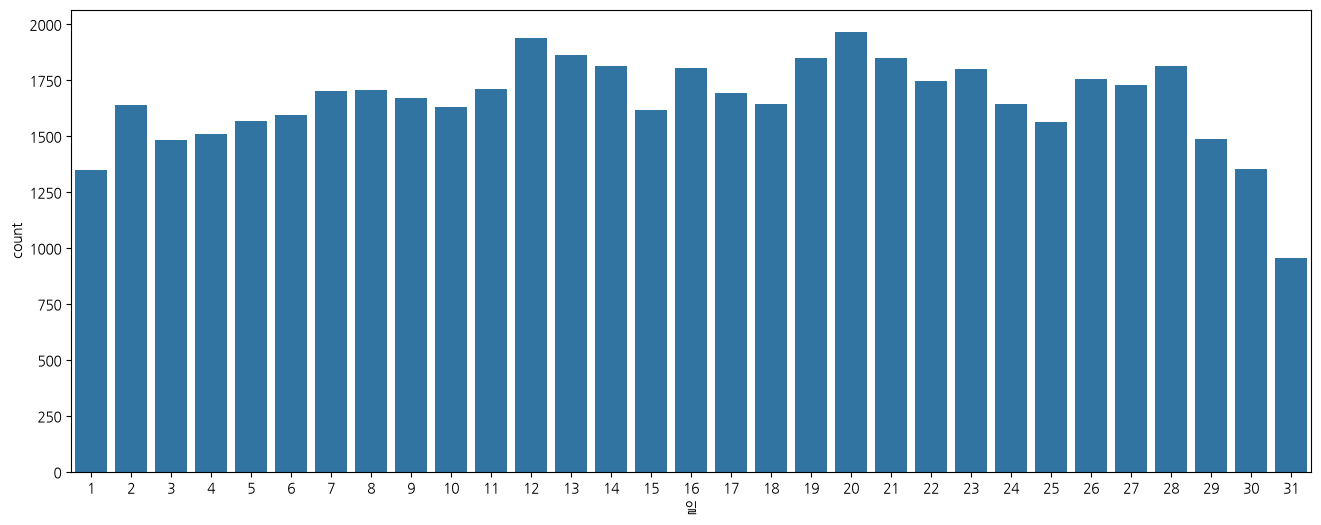

In [23]:
plt.figure(figsize=[16, 6])
sns.countplot(data=raw_df, x='일')
plt.show()

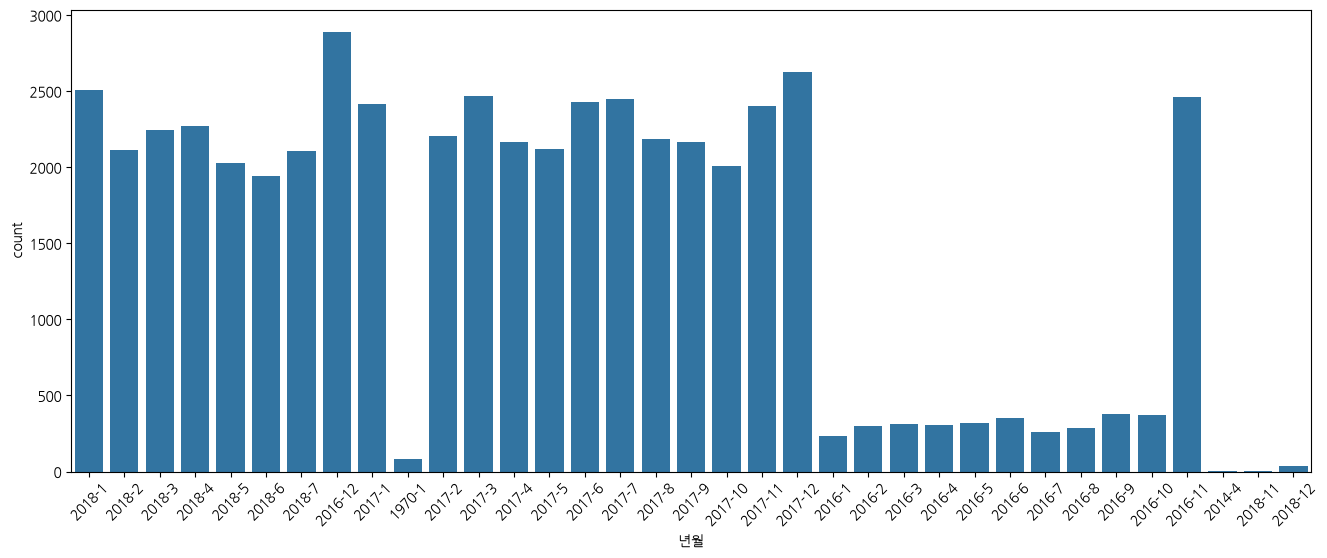

In [24]:
plt.figure(figsize=[16, 6])
sns.countplot(data=raw_df, x='년월')
plt.xticks(rotation=45)
plt.show()

그래프를 '년월'순으로 보기 위해서 년, 월을 기준으로 오름차순 정렬한다.  
sort_values() 메소드의 by에 정렬 기준으로 사용할 열을 지정하고 ascending에 정렬방식(True - 기본값, 오름차순, False - 내림차순)을 지정한다.

In [25]:
raw_df.sort_values(by=['년', '월'], ascending=True, inplace=True)
raw_df

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일
312,서울특별시장,카드,시장 등 3명,행정국 총무과,34000.0,시정 현장방문 관련 업무협의,1970-01-01 09:00:00,뼈큰감자탕 (대구 중구 명덕로),1970,1,1,1970-1,9,0,3
371,서울특별시장,카드,시장 등 4명,행정국 총무과,118000.0,시정 정책 추진 자문 간담회,1970-01-01 09:00:00,서울시청구내식당,1970,1,1,1970-1,9,0,3
398,서울특별시장,카드,직원 26명,행정국 총무과,130000.0,한양조성 도감 추진 노고 직원 격려,1970-01-01 09:00:00,빚은 (중구 세종대로길),1970,1,1,1970-1,9,0,3
408,서울특별시장,카드,시장 등 7명,행정국 총무과,151400.0,시정 일정 및 현장방문 관련 업무협의,1970-01-01 09:00:00,본도시락 (중구 소공로길),1970,1,1,1970-1,9,0,3
409,서울특별시장,현금,직원 1명,행정국 총무과,1000000.0,사망직원 유족 위로금 지급,1970-01-01 09:00:00,-,1970,1,1,1970-1,9,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51365,시민건강국,카드,박*수 주무관 등 10명,보건의료정책과,50000.0,시민건강국 현안업무 추진직원 격려 다과구입비 지급,2018-12-28 15:08:00,공차(중구 을지로1길),2018,12,28,2018-12,15,8,4
51366,시민건강국,카드,양*수 주무관 등 8명,보건의료정책과,150000.0,업무유관기관 근무자 격려 다과구입비 지급,2018-12-28 15:03:00,미스터피자(중구 무교동1),2018,12,28,2018-12,15,3,4
51367,시민건강국,카드,시민건강국장 등 10명,보건의료정책과,173920.0,보충형 공보험 제도 검토회의 추진관련 다과 구입비 지급,2018-12-28 09:56:00,마마스(중구 무교동19),2018,12,28,2018-12,9,56,4
51368,시민건강국,카드,보건의료정책과장 등 10명,보건의료정책과,186000.0,2018년 예산사업 추진관련 유관부서 간담회비 지급,2018-12-28 18:01:00,하대포(중구 을지로3길),2018,12,28,2018-12,18,1,4


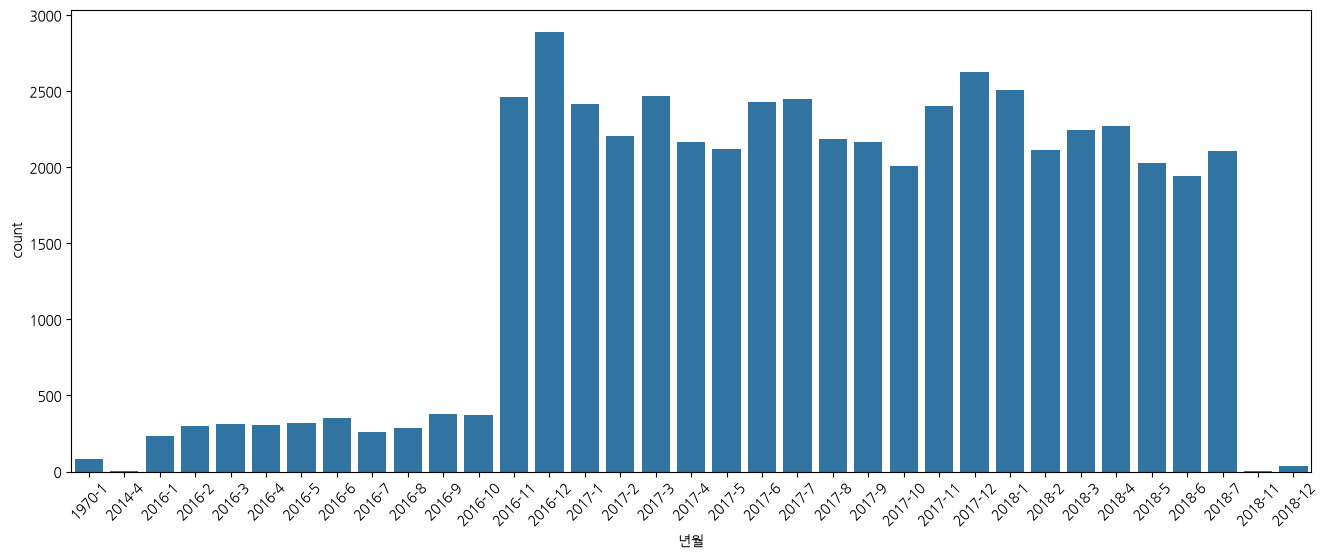

In [26]:
plt.figure(figsize=[16, 6])
sns.countplot(data=raw_df, x='년월')
plt.xticks(rotation=45)
plt.show()

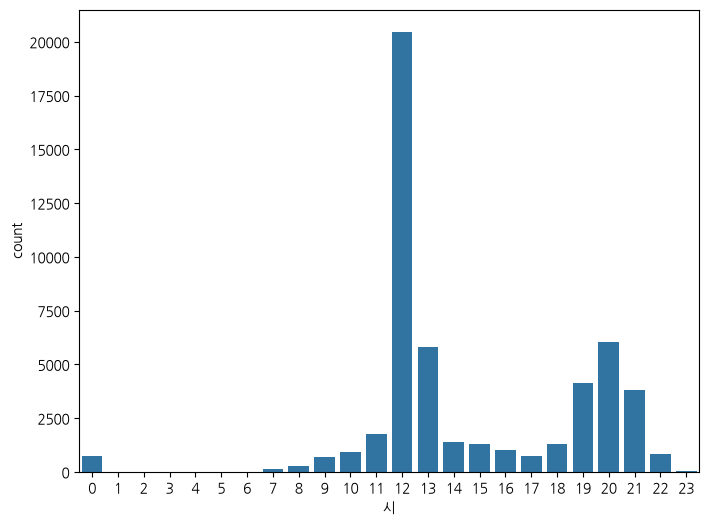

In [27]:
plt.figure(figsize=[8, 6])
sns.countplot(data=raw_df, x='시')
plt.show()

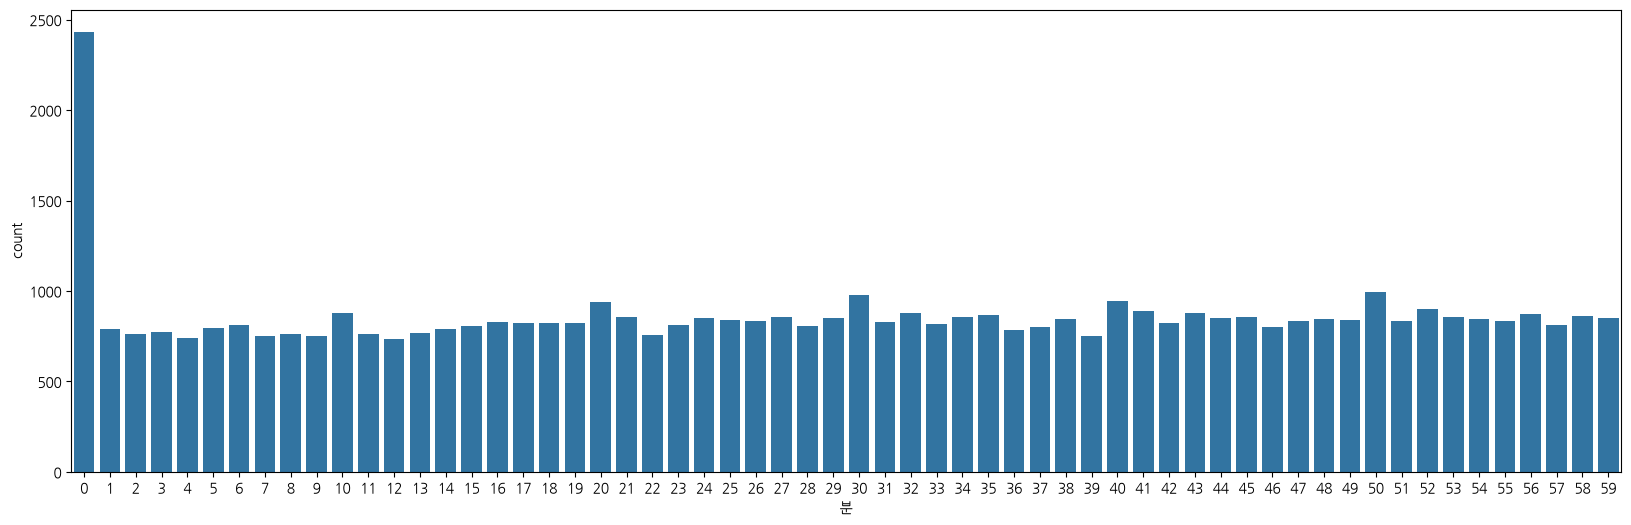

In [28]:
plt.figure(figsize=[20, 6])
sns.countplot(data=raw_df, x='분')
plt.show()

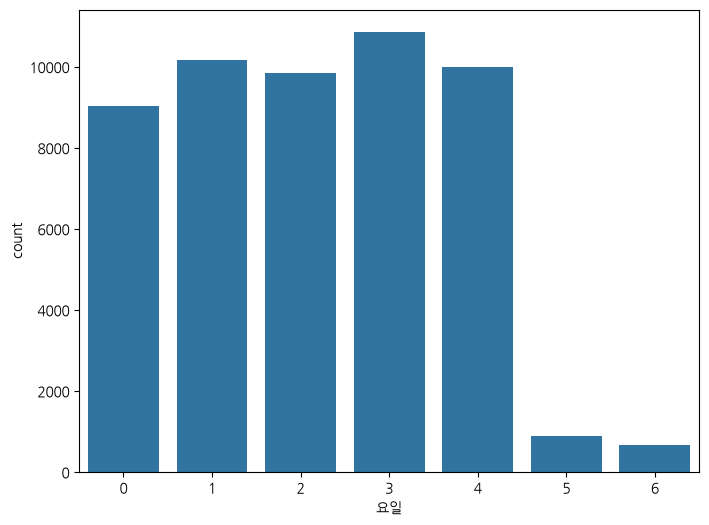

In [29]:
plt.figure(figsize=[8, 6])
sns.countplot(data=raw_df, x='요일')
plt.show()

요일이 0(월), 1(화), 2(수), 3(목), 4(금), 5(토), 6(일)와 같이 표시되므로 요일을 문자로 저장하는 파생 변수를 추가한다.

In [30]:
week_dict = {0: '월', 1: '화', 2: '수', 3: '목', 4: '금', 5: '토', 6: '일'}
week_dict

{0: '월', 1: '화', 2: '수', 3: '목', 4: '금', 5: '토', 6: '일'}

apply() 메소드로 lambda 식을 실행해서 일괄 적용한다.  
apply() 메소드가 실행되면 '요일' 열에 저장된 데이터가 한 건씩 lambda 뒤의 변수 week로 전달되고 전달받은 데이터로 ':'뒤의 식을 실행해서 일괄 적용된다.

In [31]:
raw_df['요일_한글'] = raw_df.요일.apply(lambda week: week_dict[week] + '요일')
raw_df

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일,요일_한글
312,서울특별시장,카드,시장 등 3명,행정국 총무과,34000.0,시정 현장방문 관련 업무협의,1970-01-01 09:00:00,뼈큰감자탕 (대구 중구 명덕로),1970,1,1,1970-1,9,0,3,목요일
371,서울특별시장,카드,시장 등 4명,행정국 총무과,118000.0,시정 정책 추진 자문 간담회,1970-01-01 09:00:00,서울시청구내식당,1970,1,1,1970-1,9,0,3,목요일
398,서울특별시장,카드,직원 26명,행정국 총무과,130000.0,한양조성 도감 추진 노고 직원 격려,1970-01-01 09:00:00,빚은 (중구 세종대로길),1970,1,1,1970-1,9,0,3,목요일
408,서울특별시장,카드,시장 등 7명,행정국 총무과,151400.0,시정 일정 및 현장방문 관련 업무협의,1970-01-01 09:00:00,본도시락 (중구 소공로길),1970,1,1,1970-1,9,0,3,목요일
409,서울특별시장,현금,직원 1명,행정국 총무과,1000000.0,사망직원 유족 위로금 지급,1970-01-01 09:00:00,-,1970,1,1,1970-1,9,0,3,목요일
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51365,시민건강국,카드,박*수 주무관 등 10명,보건의료정책과,50000.0,시민건강국 현안업무 추진직원 격려 다과구입비 지급,2018-12-28 15:08:00,공차(중구 을지로1길),2018,12,28,2018-12,15,8,4,금요일
51366,시민건강국,카드,양*수 주무관 등 8명,보건의료정책과,150000.0,업무유관기관 근무자 격려 다과구입비 지급,2018-12-28 15:03:00,미스터피자(중구 무교동1),2018,12,28,2018-12,15,3,4,금요일
51367,시민건강국,카드,시민건강국장 등 10명,보건의료정책과,173920.0,보충형 공보험 제도 검토회의 추진관련 다과 구입비 지급,2018-12-28 09:56:00,마마스(중구 무교동19),2018,12,28,2018-12,9,56,4,금요일
51368,시민건강국,카드,보건의료정책과장 등 10명,보건의료정책과,186000.0,2018년 예산사업 추진관련 유관부서 간담회비 지급,2018-12-28 18:01:00,하대포(중구 을지로3길),2018,12,28,2018-12,18,1,4,금요일


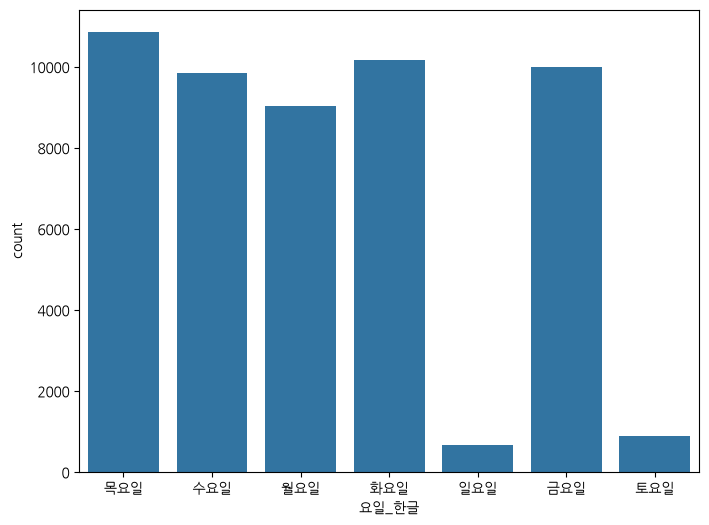

In [32]:
plt.figure(figsize=[8, 6])
sns.countplot(data=raw_df, x='요일_한글')
plt.show()

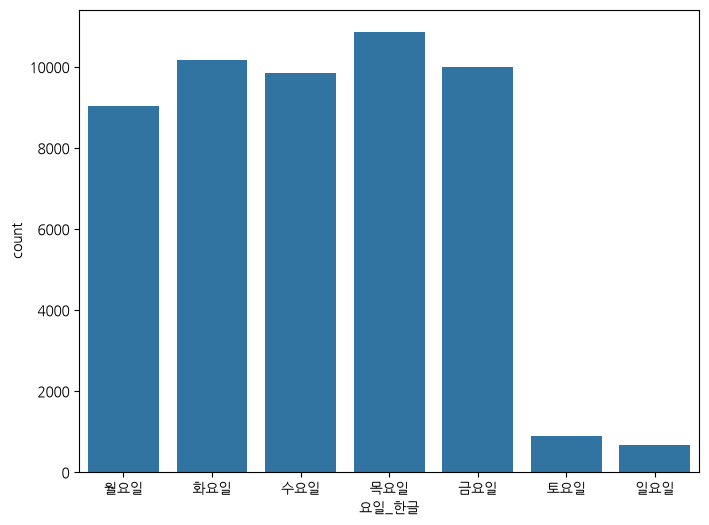

In [33]:
plt.figure(figsize=[8, 6])
sns.countplot(data=raw_df.sort_values(by=['요일']), x='요일_한글')
plt.show()

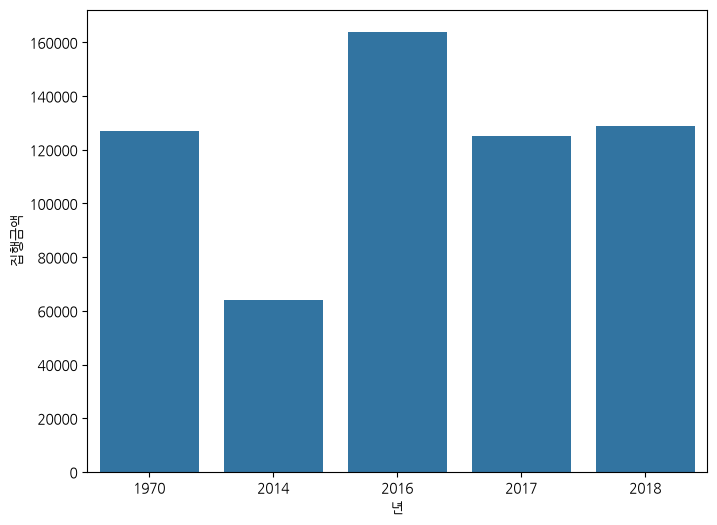

In [34]:
plt.figure(figsize=[8, 6])
sns.barplot(data=raw_df, x='년', y='집행금액', errorbar=None)
plt.show()

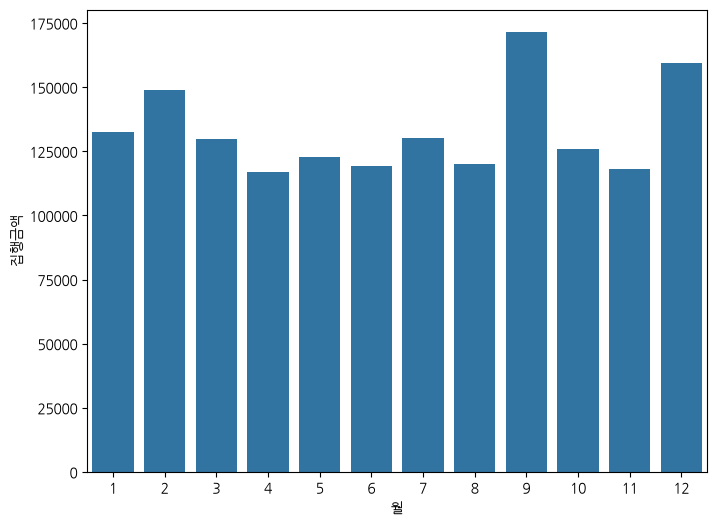

In [35]:
plt.figure(figsize=[8, 6])
sns.barplot(data=raw_df, x='월', y='집행금액', errorbar=None)
plt.show()

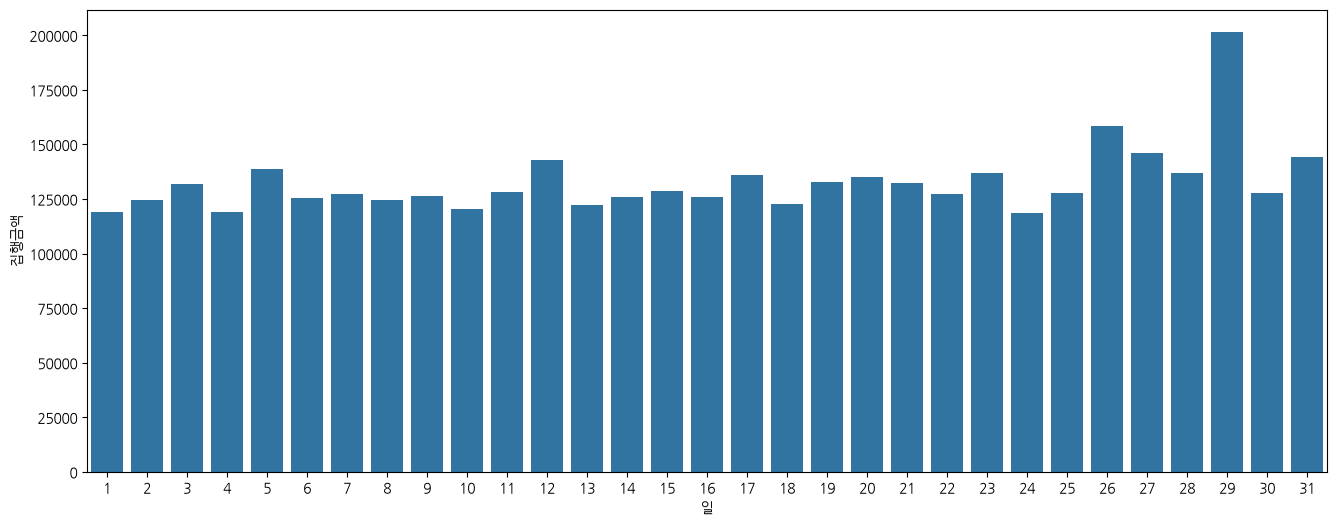

In [36]:
plt.figure(figsize=[16, 6])
sns.barplot(data=raw_df, x='일', y='집행금액', errorbar=None)
plt.show()

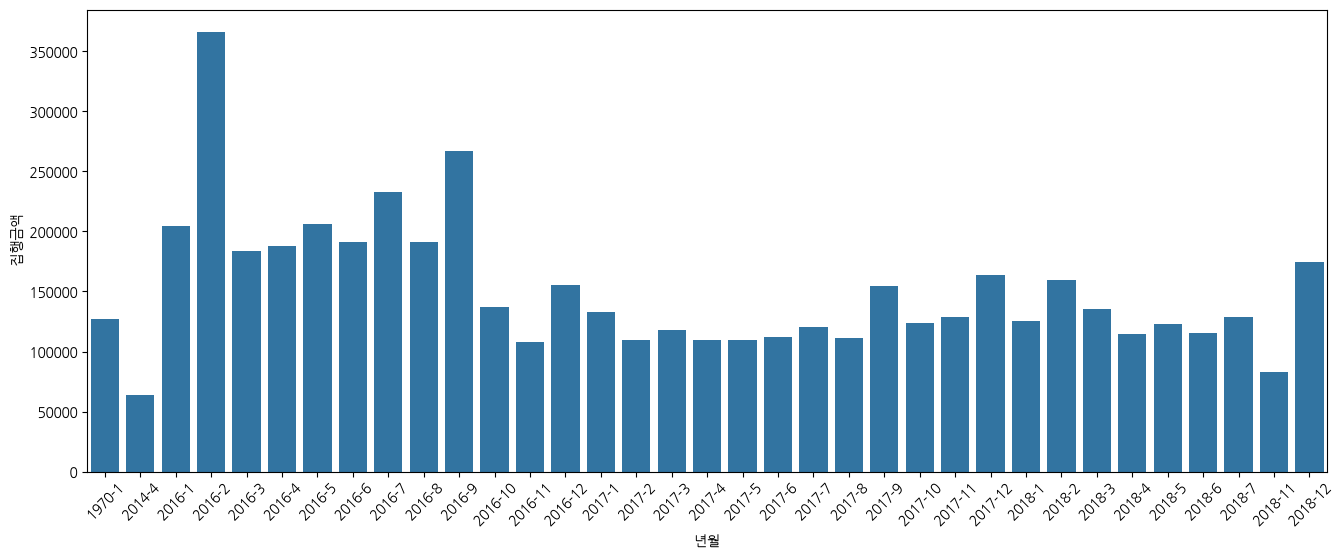

In [37]:
plt.figure(figsize=[16, 6])
sns.barplot(data=raw_df, x='년월', y='집행금액', errorbar=None)
plt.xticks(rotation=45)
plt.show()

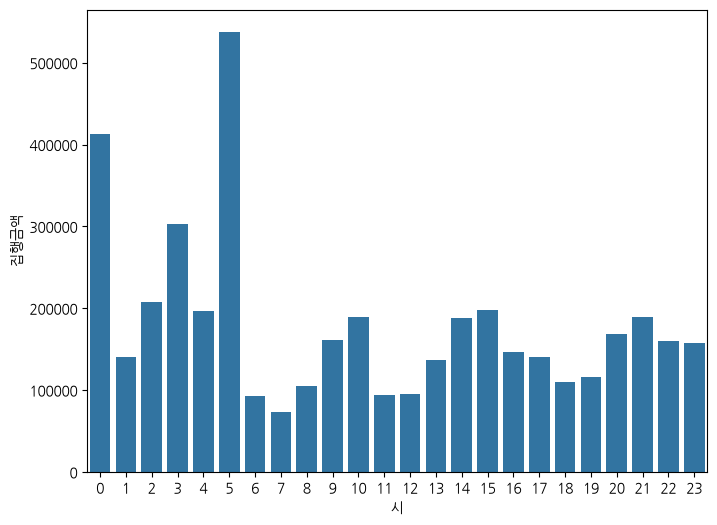

In [38]:
plt.figure(figsize=[8, 6])
sns.barplot(data=raw_df, x='시', y='집행금액', errorbar=None)
plt.show()

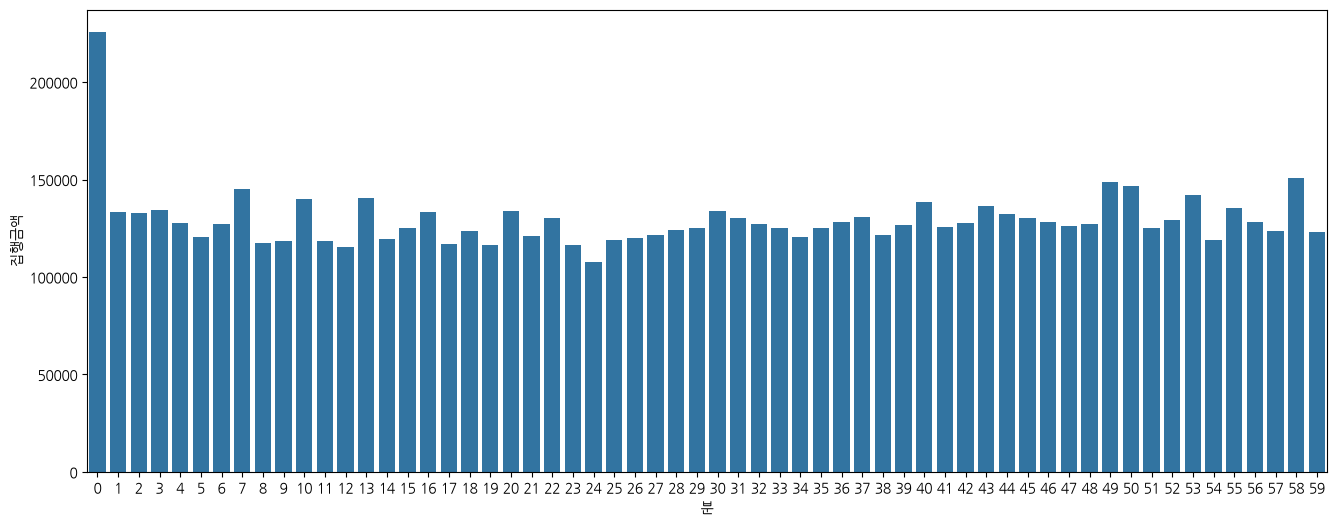

In [39]:
plt.figure(figsize=[16, 6])
sns.barplot(data=raw_df, x='분', y='집행금액', errorbar=None)
plt.show()

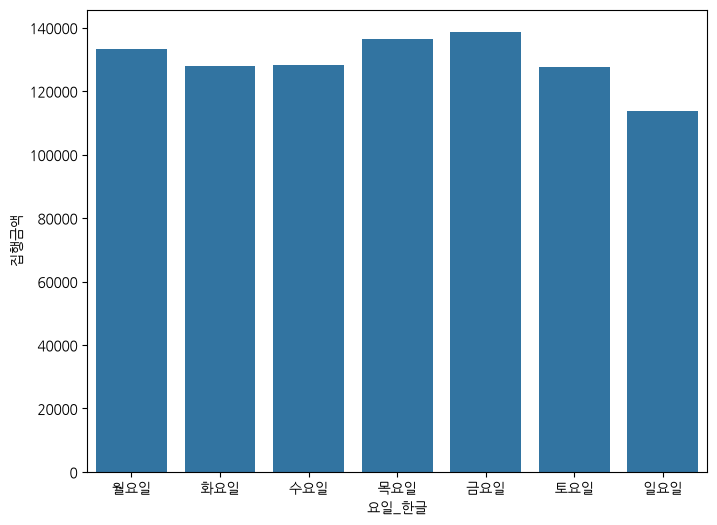

In [40]:
plt.figure(figsize=[8, 6])
sns.barplot(data=raw_df.sort_values(by=['요일']), x='요일_한글', y='집행금액', errorbar=None)
plt.show()

# 집행목적 띄어쓰기 단위 워드클라우드

In [41]:
raw_df

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일,요일_한글
312,서울특별시장,카드,시장 등 3명,행정국 총무과,34000.0,시정 현장방문 관련 업무협의,1970-01-01 09:00:00,뼈큰감자탕 (대구 중구 명덕로),1970,1,1,1970-1,9,0,3,목요일
371,서울특별시장,카드,시장 등 4명,행정국 총무과,118000.0,시정 정책 추진 자문 간담회,1970-01-01 09:00:00,서울시청구내식당,1970,1,1,1970-1,9,0,3,목요일
398,서울특별시장,카드,직원 26명,행정국 총무과,130000.0,한양조성 도감 추진 노고 직원 격려,1970-01-01 09:00:00,빚은 (중구 세종대로길),1970,1,1,1970-1,9,0,3,목요일
408,서울특별시장,카드,시장 등 7명,행정국 총무과,151400.0,시정 일정 및 현장방문 관련 업무협의,1970-01-01 09:00:00,본도시락 (중구 소공로길),1970,1,1,1970-1,9,0,3,목요일
409,서울특별시장,현금,직원 1명,행정국 총무과,1000000.0,사망직원 유족 위로금 지급,1970-01-01 09:00:00,-,1970,1,1,1970-1,9,0,3,목요일
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51365,시민건강국,카드,박*수 주무관 등 10명,보건의료정책과,50000.0,시민건강국 현안업무 추진직원 격려 다과구입비 지급,2018-12-28 15:08:00,공차(중구 을지로1길),2018,12,28,2018-12,15,8,4,금요일
51366,시민건강국,카드,양*수 주무관 등 8명,보건의료정책과,150000.0,업무유관기관 근무자 격려 다과구입비 지급,2018-12-28 15:03:00,미스터피자(중구 무교동1),2018,12,28,2018-12,15,3,4,금요일
51367,시민건강국,카드,시민건강국장 등 10명,보건의료정책과,173920.0,보충형 공보험 제도 검토회의 추진관련 다과 구입비 지급,2018-12-28 09:56:00,마마스(중구 무교동19),2018,12,28,2018-12,9,56,4,금요일
51368,시민건강국,카드,보건의료정책과장 등 10명,보건의료정책과,186000.0,2018년 예산사업 추진관련 유관부서 간담회비 지급,2018-12-28 18:01:00,하대포(중구 을지로3길),2018,12,28,2018-12,18,1,4,금요일


집행목적이 누락값인 데이터가 존재하므로 누락값을 fillna() 메소드를 사용해서 공백으로 채워준다.

In [42]:
raw_df[raw_df.집행목적.isnull()]

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일,요일_한글
14256,여성가족정책실,카드,출산장려팀장외 4명,여성가족정책실 가족담당관,30000.0,NaN,2017-02-01 12:03:00,복성각 (서울 중구 덕수궁길 7),2017,2,1,2017-2,12,3,2,수요일
14257,여성가족정책실,카드,가족정책팀장외 3명,여성가족정책실 가족담당관,21500.0,NaN,2017-02-01 15:30:00,마포만두 (서울 중구 남대문로9길 51),2017,2,1,2017-2,15,30,2,수요일
14258,여성가족정책실,카드,가족담당관외 5명,여성가족정책실 가족담당관,56500.0,NaN,2017-02-10 09:48:00,파스쿠찌종각알파빌딩 (서울 종로구 종로),2017,2,10,2017-2,9,48,4,금요일
14259,여성가족정책실,카드,가족담당관외 6명,여성가족정책실 가족담당관,8000.0,NaN,2017-02-10 09:54:00,파리바게뜨 종로시그 (서울 종로구 종로),2017,2,10,2017-2,9,54,4,금요일
14260,여성가족정책실,카드,가족담당관외 8명,여성가족정책실 가족담당관,117000.0,NaN,2017-02-10 12:14:00,（주）뚜리삼 (서울 중구 무교동),2017,2,10,2017-2,12,14,4,금요일
14261,여성가족정책실,카드,출산장려팀장외 4명,여성가족정책실 가족담당관,87500.0,NaN,2017-02-14 12:55:00,동성각 (서울 종로구 새문안로9길 29-2),2017,2,14,2017-2,12,55,1,화요일
14262,여성가족정책실,카드,가족담당관외 20명,여성가족정책실 가족담당관,62000.0,NaN,2017-02-21 19:37:00,갯마을낙지 (서울 중구 을지로1길 32),2017,2,21,2017-2,19,37,1,화요일
14263,여성가족정책실,카드,아동복지권리팀장외 3명,여성가족정책실 가족담당관,70000.0,NaN,2017-02-22 16:55:00,행복한하루소바 (서울 중구 무교로),2017,2,22,2017-2,16,55,2,수요일
14264,여성가족정책실,카드,가족정책팀장외 5명,여성가족정책실 가족담당관,125000.0,NaN,2017-02-22 21:36:00,신촌서서갈비（북창본 (서울 중구 세종대로12길 25),2017,2,22,2017-2,21,36,2,수요일
14265,여성가족정책실,카드,출산장려팀장외 3명,여성가족정책실 가족담당관,40500.0,NaN,2017-02-23 12:07:00,포베이무교점 (서울 중구 무교동),2017,2,23,2017-2,12,7,3,목요일


In [43]:
raw_df['집행목적'] = raw_df.집행목적.fillna('')
raw_df[raw_df.집행목적.isnull()]

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일,요일_한글


워드클라우드를 만들기 위해서 집행목적 열에 입력된 데이터들을 join() 메소드로 공백을 구분자로 해서 하나의 문자열로 연결한다.

In [44]:
text = ' '.join(raw_df.집행목적)
text[:100]

'시정 현장방문 관련 업무협의 시정 정책 추진 자문 간담회 한양조성 도감 추진 노고 직원 격려 시정 일정 및 현장방문 관련 업무협의 사망직원 유족 위로금 지급 시정 정책 추진 자문 '

워드클라우드를 만든다.

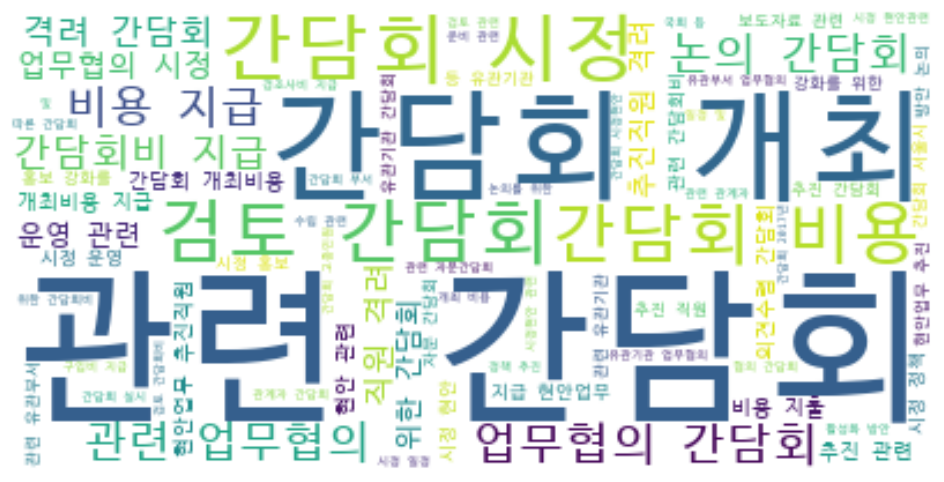

In [45]:
wc = WordCloud(
    max_font_size=100,
    max_words=200,
    background_color='white',
    font_path='C:\\Users\\PC\\AppData\\Local\\Microsoft\\Windows\\Fonts\\D2Coding-Regular.ttf'
).generate(text)

plt.figure(figsize=[12, 6])
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()

In [46]:
text = text.replace('간담회', '')

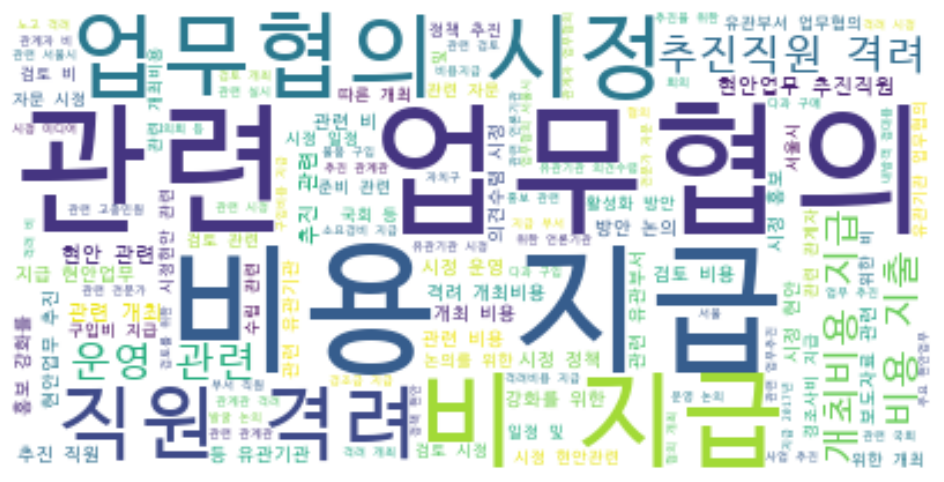

In [47]:
wc = WordCloud(
    max_font_size=100,
    max_words=200,
    background_color='white',
    font_path='C:\\Users\\PC\\AppData\\Local\\Microsoft\\Windows\\Fonts\\D2Coding-Regular.ttf'
).generate(text)

plt.figure(figsize=[12, 6])
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()

# 집행목적 형태소 단위 워드클라우드

형태소 분석에 필요한 라이브러리 Okt와 단어의 개수를 세는 라이브러리 nltk를 import 하고 형태소 분석 객체를 만든다.

In [48]:
from konlpy.tag import Okt
import nltk
okt = Okt()

워드클라우드로 만들려는 문자열에서 명사만 추출한다.

In [49]:
tokens = okt.nouns(text)
print(len(tokens))
tokens

351963


['시정',
 '현장',
 '방문',
 '관련',
 '업무',
 '협의',
 '시정',
 '정책',
 '추진',
 '자문',
 '조성',
 '도감',
 '추진',
 '노고',
 '직원',
 '격려',
 '시정',
 '일정',
 '및',
 '현장',
 '방문',
 '관련',
 '업무',
 '협의',
 '사망',
 '직원',
 '유족',
 '위로',
 '금',
 '지급',
 '시정',
 '정책',
 '추진',
 '자문',
 '결혼',
 '축하',
 '품',
 '구입',
 '비',
 '지출',
 '시정',
 '노고',
 '직원',
 '생일',
 '축하',
 '품',
 '구입',
 '비',
 '지급',
 '시정',
 '종교',
 '정책',
 '관련',
 '시정',
 '정책',
 '추진',
 '자문',
 '시정',
 '정책',
 '추진',
 '자문',
 '시정',
 '정책',
 '현안',
 '관련',
 '시정',
 '사회',
 '체육',
 '활성화',
 '관련',
 '시정',
 '정책',
 '시행',
 '관련',
 '업무',
 '협의',
 '시정',
 '주요',
 '정책',
 '관련',
 '업무',
 '협의',
 '장애인',
 '복지',
 '사업',
 '예산',
 '심의',
 '관련',
 '상임',
 '위',
 '예산안',
 '심의',
 '및',
 '증감',
 '액',
 '사업',
 '검토',
 '보건',
 '복지',
 '위원회',
 '예산안',
 '예비',
 '심사',
 '관련',
 '부서',
 '운영',
 '소요',
 '경비',
 '차류',
 '등',
 '지급',
 '부서',
 '운영',
 '필요',
 '물품',
 '구입',
 '장애인',
 '문화',
 '공모',
 '사업',
 '추진',
 '관련',
 '중',
 '증장',
 '애인',
 '자산',
 '형성',
 '지원',
 '사업',
 '논의',
 '장애인',
 '시설',
 '보조금',
 '지원',
 '및',
 '점검',
 '관련',
 '민간',
 '위탁',
 '재계약',
 '및',
 '장애인',
 '보조',
 '

불용어를 제거한다.

In [50]:
ko = nltk.Text(tokens)
print(len(ko))
print(len(ko.vocab().most_common()))
ko.vocab().most_common(1000)

351963
6881


[('관련', 22616),
 ('업무', 12066),
 ('지급', 9735),
 ('추진', 8490),
 ('협의', 7582),
 ('시정', 7443),
 ('개최', 7123),
 ('비용', 6961),
 ('현안', 6661),
 ('직원', 6428),
 ('격려', 6162),
 ('검토', 5672),
 ('운영', 5122),
 ('위', 4354),
 ('비', 4002),
 ('사업', 3743),
 ('논의', 3490),
 ('서울', 3285),
 ('방안', 3028),
 ('및', 2922),
 ('부서', 2904),
 ('정책', 2706),
 ('유관', 2337),
 ('홍보', 2248),
 ('등', 2126),
 ('회의', 2108),
 ('기관', 2088),
 ('구입', 2001),
 ('지원', 1908),
 ('지출', 1849),
 ('계획', 1841),
 ('개선', 1616),
 ('다과', 1561),
 ('준비', 1434),
 ('관', 1431),
 ('위원회', 1417),
 ('의견', 1371),
 ('수렴', 1304),
 ('회', 1301),
 ('시민', 1300),
 ('자문', 1272),
 ('점검', 1252),
 ('서울시', 1239),
 ('관계자', 1227),
 ('협력', 1207),
 ('보고', 1191),
 ('시설', 1177),
 ('활성화', 1143),
 ('교육', 1139),
 ('구매', 1076),
 ('제', 1072),
 ('센터', 1070),
 ('관리', 1060),
 ('수립', 1027),
 ('감사', 1016),
 ('현장', 978),
 ('강화', 951),
 ('도시', 950),
 ('행정', 923),
 ('행사', 913),
 ('문화', 908),
 ('평가', 906),
 ('보도자료', 839),
 ('물품', 835),
 ('조사', 824),
 ('혁신', 820),
 ('국회', 799),
 ('사회'

In [51]:
tokens = [token for token in tokens if len(token) > 1]
stopwords = ['관련', '업무']
tokens = [token for token in tokens if token not in stopwords]

In [52]:
text = dict(ko.vocab().most_common(1000))

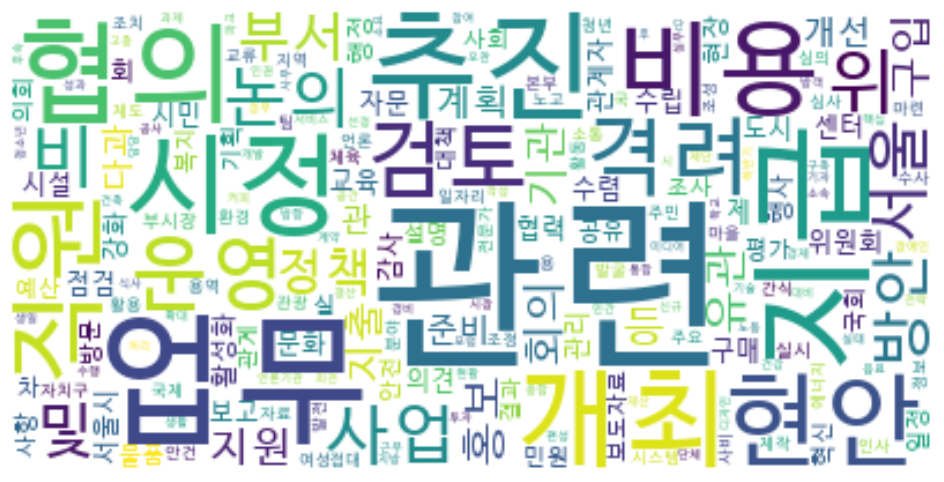

In [53]:
wc = WordCloud(
    max_font_size=80,
    max_words=200,
    background_color='white',
    font_path='C:\\Users\\PC\\AppData\\Local\\Microsoft\\Windows\\Fonts\\D2Coding-Regular.ttf'
).generate_from_frequencies(text)

plt.figure(figsize=[12, 6])
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()

# 집행장소 워드클라우드 => 공무원 맛집

집행장소가 누락값인 데이터가 존재하므로 누락값을 fillna() 메소드를 사용해서 공백으로 채워준다.

In [54]:
raw_df[raw_df.집행장소.isnull()]

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일,요일_한글
21925,행정2부시장,현금,행정2부시장,행정2부시장,50000.0,용산구도시관리국직원 경조사비 지급,2016-01-09,NaN,2016,1,9,2016-1,0,0,5,토요일
21938,행정2부시장,현금,행정2부시장,행정2부시장,50000.0,한강사업본부직원경조사비 지급 지급,2016-01-16,NaN,2016,1,16,2016-1,0,0,5,토요일
21946,행정2부시장,현금,행정2부시장,행정2부시장,50000.0,도시재생본부직원경조사비 지급,2016-01-22,NaN,2016,1,22,2016-1,0,0,4,금요일
21947,행정2부시장,현금,행정2부시장,행정2부시장,50000.0,강북구기획재정국직원 경조사비 지급,2016-01-23,NaN,2016,1,23,2016-1,0,0,5,토요일
21948,행정2부시장,현금,행정2부시장,행정2부시장,50000.0,도시기반시설본부직원 경조사비 지급,2016-01-23,NaN,2016,1,23,2016-1,0,0,5,토요일
21976,행정2부시장,현금,행정2부시장,행정2부시장,50000.0,물순환안전국직원경조사비 지급,2016-02-08,NaN,2016,2,8,2016-2,0,0,0,월요일
21977,행정2부시장,현금,행정2부시장,행정2부시장,50000.0,중부공원녹지사업소직원경조사비 지급,2016-02-08,NaN,2016,2,8,2016-2,0,0,0,월요일
21982,행정2부시장,현금,행정2부시장,행정2부시장,50000.0,상수도사업본부직원경조사비 지급,2016-02-14,NaN,2016,2,14,2016-2,0,0,6,일요일
21983,행정2부시장,현금,행정2부시장,행정2부시장,50000.0,노원구도시계획국직원 경조사비 지급,2016-02-14,NaN,2016,2,14,2016-2,0,0,6,일요일
21992,행정2부시장,현금,행정2부시장,행정2부시장,50000.0,소방재난본부직원경조사비 지급,2016-02-17,NaN,2016,2,17,2016-2,0,0,2,수요일


In [55]:
raw_df['집행장소'] = raw_df.집행장소.fillna('')
raw_df[raw_df.집행장소.isnull()]

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일,요일_한글


집행장소가 '-', '0'인 데이터가 존재하므로 공백으로 채워준다.

In [56]:
raw_df[raw_df.집행장소 == '-']

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일,요일_한글
409,서울특별시장,현금,직원 1명,행정국 총무과,1000000.0,사망직원 유족 위로금 지급,1970-01-01 09:00:00,-,1970,1,1,1970-1,9,0,3,목요일
13504,행정1부시장,현금,-,행정1부시장,150000.0,축.부의금 지급(3명),2016-01-08 00:00:00,-,2016,1,8,2016-1,0,0,4,금요일
13512,행정1부시장,현금,-,행정1부시장,100000.0,부의금 지급(2명),2016-01-12 00:00:00,-,2016,1,12,2016-1,0,0,1,화요일
13529,행정1부시장,현금,-,행정1부시장,150000.0,축.부의금 지급(3명),2016-01-21 00:00:00,-,2016,1,21,2016-1,0,0,3,목요일
13542,행정1부시장,현금,-,행정1부시장,150000.0,축.부의금 지급(3명),2016-01-28 00:00:00,-,2016,1,28,2016-1,0,0,3,목요일
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16877,비상기획관,현금,비상기획관,민방위담당관,50000.0,"경조사비 지급(민방위담당관 김ㅇㅇ주무관 시모상, 비상기획관)",2018-07-19 00:00:00,-,2018,7,19,2018-7,0,0,3,목요일
27492,기획조정실,현금,기획조정실장,기획조정실 기획담당관,50000.0,소속 상근 직원 경조사비 지급(부의금),2018-07-03 00:00:00,-,2018,7,3,2018-7,0,0,1,화요일
35084,문화본부,현금,문화본부장,문화본부 문화정책과,50000.0,문화본부 소속직원 경조사비 지급,2018-07-23 00:00:00,-,2018,7,23,2018-7,0,0,0,월요일
50946,시민건강국,현금,시민건강국장,시민건강국 보건의료정책과,50000.0,소속 상근직원 경조사비 지급,2018-07-22 00:00:00,-,2018,7,22,2018-7,0,0,6,일요일


In [57]:
raw_df.loc[raw_df.집행장소 == '-', '집행장소'] = ''
raw_df[raw_df.집행장소 == '-']

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일,요일_한글


In [58]:
raw_df[raw_df.집행장소 == '0']

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일,요일_한글
51,서울특별시장,현금,1명,행정국 총무과,1000000.0,직원 사망 유족 위로금,2018-01-15,0,2018,1,15,2018-1,0,0,0,월요일
40636,행정국,현금,행정국장,행정국 총무과,50000.0,소속 상근직원 경조사비 지급,2018-01-15,0,2018,1,15,2018-1,0,0,0,월요일
41301,행정국,현금,행정국장,행정국 총무과,50000.0,소속 상근직원 경조사비 지급,2018-01-15,0,2018,1,15,2018-1,0,0,0,월요일


In [59]:
raw_df.loc[raw_df.집행장소 == '0', '집행장소'] = ''
raw_df[raw_df.집행장소 == '0']

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일,요일_한글


집행장소에 주소가 보이기때문에 주소는 전처리를 통해 제거하고 상호명이라는 파생 변수를 추가해서 상호명만 넣어준다.  
집행장소에서 상호명만 가져오려면 '(' 앞쪽의 데이터만 가져오면 된다.

In [60]:
print('복성각 (서울 중구 덕수궁길 7)'.split('(')[0])
print('복성각'.split('(')[0])
print(''.split('(')[0])

복성각 
복성각



In [61]:
raw_df['상호명'] = raw_df.집행장소.apply(lambda x: x.split('(')[0].strip())
raw_df

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일,요일_한글,상호명
312,서울특별시장,카드,시장 등 3명,행정국 총무과,34000.0,시정 현장방문 관련 업무협의,1970-01-01 09:00:00,뼈큰감자탕 (대구 중구 명덕로),1970,1,1,1970-1,9,0,3,목요일,뼈큰감자탕
371,서울특별시장,카드,시장 등 4명,행정국 총무과,118000.0,시정 정책 추진 자문 간담회,1970-01-01 09:00:00,서울시청구내식당,1970,1,1,1970-1,9,0,3,목요일,서울시청구내식당
398,서울특별시장,카드,직원 26명,행정국 총무과,130000.0,한양조성 도감 추진 노고 직원 격려,1970-01-01 09:00:00,빚은 (중구 세종대로길),1970,1,1,1970-1,9,0,3,목요일,빚은
408,서울특별시장,카드,시장 등 7명,행정국 총무과,151400.0,시정 일정 및 현장방문 관련 업무협의,1970-01-01 09:00:00,본도시락 (중구 소공로길),1970,1,1,1970-1,9,0,3,목요일,본도시락
409,서울특별시장,현금,직원 1명,행정국 총무과,1000000.0,사망직원 유족 위로금 지급,1970-01-01 09:00:00,,1970,1,1,1970-1,9,0,3,목요일,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51365,시민건강국,카드,박*수 주무관 등 10명,보건의료정책과,50000.0,시민건강국 현안업무 추진직원 격려 다과구입비 지급,2018-12-28 15:08:00,공차(중구 을지로1길),2018,12,28,2018-12,15,8,4,금요일,공차
51366,시민건강국,카드,양*수 주무관 등 8명,보건의료정책과,150000.0,업무유관기관 근무자 격려 다과구입비 지급,2018-12-28 15:03:00,미스터피자(중구 무교동1),2018,12,28,2018-12,15,3,4,금요일,미스터피자
51367,시민건강국,카드,시민건강국장 등 10명,보건의료정책과,173920.0,보충형 공보험 제도 검토회의 추진관련 다과 구입비 지급,2018-12-28 09:56:00,마마스(중구 무교동19),2018,12,28,2018-12,9,56,4,금요일,마마스
51368,시민건강국,카드,보건의료정책과장 등 10명,보건의료정책과,186000.0,2018년 예산사업 추진관련 유관부서 간담회비 지급,2018-12-28 18:01:00,하대포(중구 을지로3길),2018,12,28,2018-12,18,1,4,금요일,하대포


불필요한(상호명이 공백인) 데이터는 제거해서 CSV 파일로 저장한다.

In [62]:
shop_df = raw_df[raw_df.상호명 != '']
shop_df.to_csv('./data/shop.csv', index=False)
shop_df

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일,요일_한글,상호명
312,서울특별시장,카드,시장 등 3명,행정국 총무과,34000.0,시정 현장방문 관련 업무협의,1970-01-01 09:00:00,뼈큰감자탕 (대구 중구 명덕로),1970,1,1,1970-1,9,0,3,목요일,뼈큰감자탕
371,서울특별시장,카드,시장 등 4명,행정국 총무과,118000.0,시정 정책 추진 자문 간담회,1970-01-01 09:00:00,서울시청구내식당,1970,1,1,1970-1,9,0,3,목요일,서울시청구내식당
398,서울특별시장,카드,직원 26명,행정국 총무과,130000.0,한양조성 도감 추진 노고 직원 격려,1970-01-01 09:00:00,빚은 (중구 세종대로길),1970,1,1,1970-1,9,0,3,목요일,빚은
408,서울특별시장,카드,시장 등 7명,행정국 총무과,151400.0,시정 일정 및 현장방문 관련 업무협의,1970-01-01 09:00:00,본도시락 (중구 소공로길),1970,1,1,1970-1,9,0,3,목요일,본도시락
410,서울특별시장,카드,시장 등 9명,행정국 총무과,250000.0,시정 정책 추진 자문 간담회,1970-01-01 09:00:00,참춫골 (중구 무교로길),1970,1,1,1970-1,9,0,3,목요일,참춫골
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51365,시민건강국,카드,박*수 주무관 등 10명,보건의료정책과,50000.0,시민건강국 현안업무 추진직원 격려 다과구입비 지급,2018-12-28 15:08:00,공차(중구 을지로1길),2018,12,28,2018-12,15,8,4,금요일,공차
51366,시민건강국,카드,양*수 주무관 등 8명,보건의료정책과,150000.0,업무유관기관 근무자 격려 다과구입비 지급,2018-12-28 15:03:00,미스터피자(중구 무교동1),2018,12,28,2018-12,15,3,4,금요일,미스터피자
51367,시민건강국,카드,시민건강국장 등 10명,보건의료정책과,173920.0,보충형 공보험 제도 검토회의 추진관련 다과 구입비 지급,2018-12-28 09:56:00,마마스(중구 무교동19),2018,12,28,2018-12,9,56,4,금요일,마마스
51368,시민건강국,카드,보건의료정책과장 등 10명,보건의료정책과,186000.0,2018년 예산사업 추진관련 유관부서 간담회비 지급,2018-12-28 18:01:00,하대포(중구 을지로3길),2018,12,28,2018-12,18,1,4,금요일,하대포


상호명 노가다

In [106]:
shop_df.상호명.value_counts()[:40]

상호명
참숯골           806
우도일식          763
서울시청매점        720
구이구이          664
바닷가작은부엌       661
곰국시집          494
파리바게뜨         490
서울시청구내식당      409
동해일식          399
무교소호정         362
동해수산          331
스타벅스          319
뚜리삼           315
라칸티나          309
한가람           308
동원참치          304
더테이블한정식       295
삼우정           278
어미가           276
제일가든          274
오리마당          259
복성각           256
월향            256
열빈            230
무교동낙지         229
남포면옥          223
포메인           205
서라벌           205
마마스           202
대상자 소속부서      199
금강산           195
오복미역          194
창고43          190
대복            189
낙동강           188
목포세발낙지        180
주식회사　동원브이아    178
산채향           176
여수바다장어        175
영덕회식당         175
Name: count, dtype: int64

In [104]:
shop_df[shop_df.상호명.str.find('주식회사') >= 0]

,소속부서,결제방법,대상인원,부서명,집행금액,집행목적,집행일시,집행장소,년,월,일,년월,시,분,요일,요일_한글,상호명
40991,행정국,카드,인재양성팀장 외 11명,일력개발과,66000.0,2017년도 행정국 예산심의 결과보고 간담회,1970-01-01 09:00:00,주식회사 동원브이아 (중구 세종대로22길),1970,1,1,1970-1,9,0,3,목요일,주식회사 동원브이아
21933,행정2부시장,카드,행정2부시장등 13명,행정2부시장,479000.0,안전총괄본부현안업무추진직원 격려,2016-01-14 21:00:00,주식회사신안촌 (종로구새문안로5길),2016,1,14,2016-1,21,0,3,목요일,주식회사신안촌
21935,행정2부시장,카드,행정2부시장등 4명,행정2부시장,92500.0,행정2부시장산하주요소송 추진 간담회,2016-01-15 13:20:00,주식회사해우리무교점 (중구남대문로9길),2016,1,15,2016-1,13,20,4,금요일,주식회사해우리무교점
21944,행정2부시장,카드,행정2부시장등 4명,행정2부시장,112000.0,주택정책시기조정추진간담회,2016-01-21 13:20:00,주식회사 동원브이아 (중구세종대로22길),2016,1,21,2016-1,13,20,3,목요일,주식회사 동원브이아
25086,정무부시장,카드,정무비서관 외 3명,시민소통기획관 시민소통담당관(정무수석실),83500.0,시정현안 관련 국회 등 유관기관 업무협의 간담회,2016-01-07 21:10:00,대만야시장주식회사(마포구 동교로),2016,1,7,2016-1,21,10,3,목요일,대만야시장주식회사
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47678,평생교육국,카드,교육정책과장 등 6명,평생교육국 교육정책과,127000.0,교육정책과 주요사업 홍보 활성화 간담회 개최비용 지급,2018-07-19 19:37:00,롯데쇼핑주식회사,2018,7,19,2018-7,19,37,3,목요일,롯데쇼핑주식회사
47681,평생교육국,카드,교육정책과 직원 15명,평생교육국 교육정책과,107000.0,부서 전출직원 격려 다과 구매비 지급,2018-07-24 19:39:00,롯데쇼핑주식회사,2018,7,24,2018-7,19,39,1,화요일,롯데쇼핑주식회사
48307,관광체육국,카드,관광정책과장 등 8명,관광체육국 관광정책과,298000.0,매력적인 테마관광프로그램 개발 관련 간담회,2018-07-18 20:37:00,"주식회사다한우(서울 중구 남대문로1길 51,탁홍희)",2018,7,18,2018-7,20,37,2,수요일,주식회사다한우
48325,관광체육국,카드,관광체육국장 등 3명,관광체육국 관광정책과,50000.0,서울순례길 현장방문 관련 간담회,2018-07-30 12:21:00,"주식회사 청진옥해장(서울 종로구 종로3길 32,최준용)",2018,7,30,2018-7,12,21,0,월요일,주식회사 청진옥해장


In [105]:
set(shop_df[shop_df.상호명.str.find('주식회사') >= 0].상호명)

{'개미푸드랩\u3000주식회사',
 '광화문해리주식회사',
 '대만야시장주식회사',
 '두레에프엔씨주식회사',
 '디에스디엘주식회사',
 '디오브루잉주식회사',
 '롯데쇼핑주식회사',
 '롯데쇼핑주식회사 서울 중구 소공동',
 '롯데쇼핑주식회사-핫텐도',
 '마르셀／주식회사\u3000마',
 '메구미／주식회사은혜',
 '사유\u3000주식회사\u3000（ 용산구 이태원로54길 5)',
 '선일통산주식회사',
 '스파클주식회사',
 '시마스시／주식회사',
 '원조하루밥상주식회사',
 '주식회사 다한우',
 '주식회사 더행복',
 '주식회사 동원브이아',
 '주식회사 동원브이아이피',
 '주식회사 동원브이아이피참치',
 '주식회사 마카오도우',
 '주식회사 무화잠',
 '주식회사 어반가든',
 '주식회사 월화고기',
 '주식회사 이태리총각',
 '주식회사 중림장',
 '주식회사 진곰',
 '주식회사 철철',
 '주식회사 청진옥해장',
 '주식회사 한우',
 '주식회사 해우리무교점',
 '주식회사\u3000남산돈까스',
 '주식회사\u3000당산허브족',
 '주식회사\u3000더행복',
 '주식회사\u3000동원브이아',
 '주식회사\u3000동원브이아 서울 중구 세종대로',
 '주식회사\u3000동원브이아 서울 중구 세종대로 135',
 '주식회사\u3000동원브이아 서울 중구 세종대로22길',
 '주식회사\u3000동원브이아 중구 세종대로22길',
 '주식회사\u3000동원브이아서울 중구 세종대로22길',
 '주식회사\u3000동원브이아이피',
 '주식회사\u3000동원브이아이피 참치',
 '주식회사\u3000동원브이아이피참치',
 '주식회사\u3000동원브이아피',
 '주식회사\u3000무화잠',
 '주식회사\u3000세원위\u3000종',
 '주식회사\u3000시드버거',
 '주식회사\u3000알트윈／다',
 '주식회사\u3000알트윈／다쯔미',
 '주식회사\u3000어반가든',
 '주식회사\u3000에이치앤더',
 '주식회사\u3000유성집',
 '주식회

In [100]:
shop_df.loc[shop_df.상호명.str.find('뚜리삼') >= 0, '상호명'] = '뚜리삼'

데이터 전처리된 결과에서 워드클라우드로 구성할 데이터만 추출한다.  
판다스의 DataFrame를 이용해서 데이터프레임을 만들때 첫 번째 열을 인덱스로 사용하지 않으려면 reset_index()를 실행한다.

In [111]:
top_200 = pd.DataFrame(shop_df.상호명.value_counts()[:200]).reset_index()
top_200

,상호명,count
0,참숯골,806
1,우도일식,763
2,서울시청매점,720
3,구이구이,664
4,바닷가작은부엌,661
...,...,...
195,도미노피자,50
196,한성,50
197,신안촌,49
198,혼신마켓,49


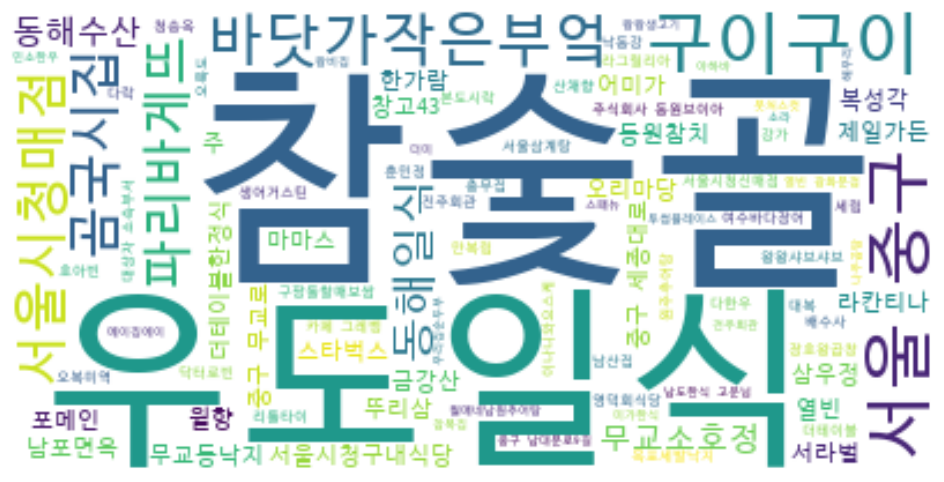

In [113]:
wc = WordCloud(
    max_font_size=100,
    max_words=200,
    background_color='white',
    font_path='C:\\Users\\PC\\AppData\\Local\\Microsoft\\Windows\\Fonts\\D2Coding-Regular.ttf'
).generate(' '.join(shop_df.상호명))

plt.figure(figsize=[12, 6])
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()